# Prédiction du chiffre d’affaires annuel des entreprises
## Comparaison de la régression linéaire, Ridge, Lasso et SGD

**Auteur : Ahmadou Moukhtar Kane** — Projet pédagogique de régression supervisée.

### Problématique
Peut-on estimer le chiffre d’affaires annuel d’une entreprise à partir de ses caractéristiques numériques et catégorielles ? Une régularisation ou un autre algorithme d’optimisation apporte-t-il un gain par rapport à la régression linéaire classique ?

### Objectifs
- Explorer les données et vérifier leur qualité.
- Encoder les catégories et standardiser les variables numériques.
- Tester une sélection par corrélation de Pearson, puis examiner la multicolinéarité.
- Comparer quatre approches linéaires avec R², MAE, MSE et RMSE.
- Examiner les résidus et discuter les limites.

### Données et périmètre
Les sorties fournies décrivent **1 200 observations et 13 colonnes**, dont une cible : `chiffre_affaires_annuel`. La séparation 80/20 correspond à **960 observations d’entraînement et 240 de test**. Aucune valeur manquante ni ligne identique n’est signalée dans les sorties enregistrées.

La source du dataset, son caractère réel ou synthétique, la devise, la période de mesure des visites et le sens exact de `age` restent à confirmer. Les régions portent des noms égyptiens ; cela ne suffit pas à établir l’origine ou la représentativité des données.

### Exécution et statut des résultats
Placer `dataset.csv` dans le dossier du notebook et exécuter les cellules dans l’ordre. Dépendances : numpy, pandas, matplotlib, seaborn, scikit-learn, scipy et statsmodels.

**Le CSV n’était pas joint.** Les résultats d’origine sont transcrits dans la synthèse finale comme **résultats historiques à confirmer**. Les sorties intermédiaires ont été effacées afin de ne pas confondre les anciens résultats avec le code corrigé. La syntaxe et le fonctionnement ont été vérifiés séparément ; aucune nouvelle performance sur les données réelles n’est annoncée.

### Modifications techniques ciblées
- Imports des métriques et de `display` ajoutés.
- Retraits appliqués au train et au test, avant l’ajustement des modèles.
- Références catégorielles retirées avant le premier entraînement, tout en conservant le diagnostic VIF après ce premier modèle.
- Affichage des vrais coefficients de Lasso et SGD.
- Reproductibilité de SGD fixée et nombre maximal d’itérations augmenté.
- Ajout d’un graphique Q-Q, d’une référence simple et d’un tableau comparatif basé sur les noms des métriques.

Les limites de la démarche originale sont documentées ci-dessous : cette version ne prétend pas ajouter une validation croisée complète ni optimiser les hyperparamètres.

# Importation des bibliothèques

In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
#Modeles
from sklearn.linear_model import  LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.linear_model import SGDRegressor
# Prétraitement
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from pathlib import Path
from IPython.display import display
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error


---
# Étape 1 — Analyse exploratoire des données (EDA)

## 1.1 Chargement et informations générales

In [15]:
#importation des donnees
df=pd.read_csv(r"c:\Users\Administrateur\Documents\Master en intelligence Artificielle\Semestre3\IA Applique a la finance\TP1\dataset.csv")
df.head()

,age,experience_years,experience_proxy,monthly_ad_spend,website_visits,team_size,customer_rating,region,business_type,subscription_plan,noise_feature_1,noise_feature_2,annual_revenue
0,23,0,-1.28,120217.22,394762,8,4.01,Alexandria,Ecommerce,Standard,-294.95,-18.61,240086.12
1,51,29,28.75,54622.52,183214,56,2.89,Cairo,Services,Basic,-461.02,44.49,274237.97
2,46,20,23.79,41675.76,113096,141,2.89,Upper_Egypt,Manufacturing,Basic,-2156.89,-15.63,294387.86
3,37,13,15.73,13457.42,41326,91,4.64,Cairo,Services,Standard,682.77,21.51,247522.89
4,37,14,13.88,9281.03,11671,93,3.28,Cairo,Services,Standard,-1233.05,38.27,226068.17


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                1200 non-null   int64  
 1   experience_years   1200 non-null   int64  
 2   experience_proxy   1200 non-null   float64
 3   monthly_ad_spend   1200 non-null   float64
 4   website_visits     1200 non-null   int64  
 5   team_size          1200 non-null   int64  
 6   customer_rating    1200 non-null   float64
 7   region             1200 non-null   object 
 8   business_type      1200 non-null   object 
 9   subscription_plan  1200 non-null   object 
 10  noise_feature_1    1200 non-null   float64
 11  noise_feature_2    1200 non-null   float64
 12  annual_revenue     1200 non-null   float64
dtypes: float64(6), int64(4), object(3)
memory usage: 122.0+ KB


In [17]:
df = df.rename(columns={
    "age": "age",
    "experience_years": "annees_experience",
    "experience_proxy": "indicateur_experience",
    "monthly_ad_spend": "depenses_publicitaires_mensuelles",
    "website_visits": "visites_site_web",
    "team_size": "taille_equipe",
    "customer_rating": "note_clients",
    "region": "region",
    "business_type": "type_entreprise",
    "subscription_plan": "formule_abonnement",
    "noise_feature_1": "variable_bruit_1",
    "noise_feature_2": "variable_bruit_2",
    "annual_revenue": "chiffre_affaires_annuel"
})

df.head() 

,age,annees_experience,indicateur_experience,depenses_publicitaires_mensuelles,visites_site_web,taille_equipe,note_clients,region,type_entreprise,formule_abonnement,variable_bruit_1,variable_bruit_2,chiffre_affaires_annuel
0,23,0,-1.28,120217.22,394762,8,4.01,Alexandria,Ecommerce,Standard,-294.95,-18.61,240086.12
1,51,29,28.75,54622.52,183214,56,2.89,Cairo,Services,Basic,-461.02,44.49,274237.97
2,46,20,23.79,41675.76,113096,141,2.89,Upper_Egypt,Manufacturing,Basic,-2156.89,-15.63,294387.86
3,37,13,15.73,13457.42,41326,91,4.64,Cairo,Services,Standard,682.77,21.51,247522.89
4,37,14,13.88,9281.03,11671,93,3.28,Cairo,Services,Standard,-1233.05,38.27,226068.17


| Variable renommée | Description | Type attendu |
|---|---|---|
| **`age`** | Âge de la personne ou ancienneté de l’entreprise : à confirmer dans la documentation. | Numérique |
| **`annees_experience`** | Nombre d’années d’expérience. | Numérique |
| **`indicateur_experience`** | Mesure indirecte de l’expérience (*proxy*). Peut apporter une information proche de `annees_experience`. | Numérique |
| **`depenses_publicitaires_mensuelles`** | Montant dépensé chaque mois pour la publicité. La devise reste à préciser. | Numérique |
| **`visites_site_web`** | Nombre de visites sur le site web, sur une période à préciser. | Numérique |
| **`taille_equipe`** | Nombre de personnes dans l’équipe. | Numérique |
| **`note_clients`** | Note attribuée par les clients. L’échelle utilisée reste à vérifier, par exemple sur 5 ou sur 10. | Numérique |
| **`region`** | Région géographique associée à l’entreprise. | Catégorielle |
| **`type_entreprise`** | Catégorie ou type d’entreprise. | Catégorielle |
| **`formule_abonnement`** | Formule d’abonnement utilisée par l’entreprise. | Catégorielle |
| **`variable_bruit_1`** | Variable dont le nom suggère du bruit, potentiellement sans information utile pour prédire le chiffre d’affaires. | Numérique, à vérifier |
| **`variable_bruit_2`** | Deuxième variable dont le nom suggère du bruit. | Numérique, à vérifier |
| **`chiffre_affaires_annuel`** | Montant des ventes réalisées par l’entreprise sur une année. **C’est la variable cible à prédire.** | Numérique |

### Lecture du dictionnaire
La cible est une valeur continue : il s’agit donc d’une régression supervisée. Les intitulés `variable_bruit_1` et `variable_bruit_2` suggèrent du bruit mais ne prouvent pas leur inutilité sans examen. La description précise des données doit provenir de leur documentation.

## 1.2 Analyse des valeurs manquantes

In [18]:
df.isnull().sum()

age                                  0
annees_experience                    0
indicateur_experience                0
depenses_publicitaires_mensuelles    0
visites_site_web                     0
taille_equipe                        0
note_clients                         0
region                               0
type_entreprise                      0
formule_abonnement                   0
variable_bruit_1                     0
variable_bruit_2                     0
chiffre_affaires_annuel              0
dtype: int64

## 1.3 Vérification des lignes en double

In [19]:
df_duplicated=df.duplicated().sum()
df_duplicated

0

### Qualité des données observée
Les sorties du fichier source indiquent zéro valeur manquante et zéro doublon. Il n’est donc pas nécessaire d’inventer une imputation pour cette exécution. Les valeurs atypiques doivent être examinées : un point extrême n’est pas automatiquement une erreur à retirer.

## 1.4 Statistiques descriptives

In [20]:
df.describe()

,age,annees_experience,indicateur_experience,depenses_publicitaires_mensuelles,visites_site_web,taille_equipe,note_clients,variable_bruit_1,variable_bruit_2,chiffre_affaires_annuel
count,1200.000000,1200.000000,1200.000000,1200.000000,1200.00000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000
mean,40.162500,18.307500,18.779933,24208.585867,65729.14000,74.217500,3.755708,-49.640983,-1.071300,233149.783258
std,11.797333,11.743986,12.174497,20618.049145,57825.13094,42.933724,0.714649,974.443011,28.532477,49740.754481
min,20.000000,0.000000,-2.940000,2104.830000,1000.00000,2.000000,2.500000,-2974.400000,-49.980000,102938.820000
25%,30.000000,7.750000,7.937500,10991.792500,29632.25000,38.000000,3.160000,-708.180000,-25.800000,198259.660000
50%,40.000000,19.000000,19.095000,18147.650000,49457.50000,72.000000,3.780000,-38.625000,-1.710000,232717.490000
75%,51.000000,28.000000,28.915000,31169.412500,83946.75000,111.000000,4.350000,564.887500,23.482500,266027.432500
max,60.000000,38.000000,42.130000,180000.000000,544599.00000,150.000000,5.000000,4151.240000,49.970000,415128.670000


## 1.5 Distribution des variables

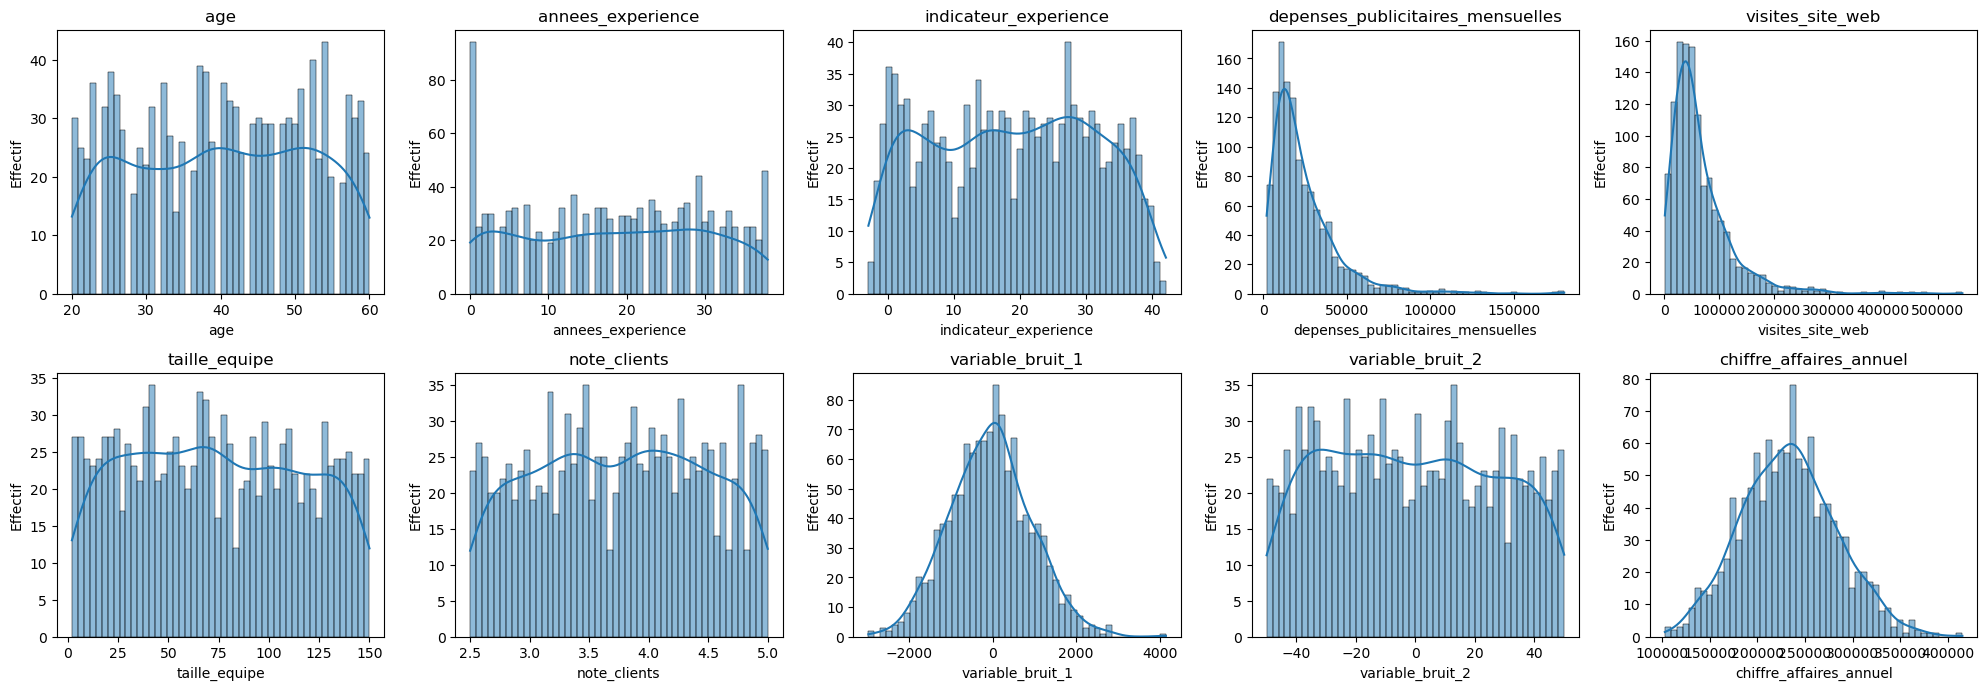

In [21]:
# Sélectionner uniquement les colonnes numériques
colonnes_numeriques = df.select_dtypes(include="number").columns

# Créer une grille de 3 lignes et 5 colonnes : 15 graphiques
fig, axs = plt.subplots(3, 5, figsize=(20, 10))

# Transformer la grille en tableau à une dimension
# pour accéder aux graphiques avec axs[i]
axs = axs.ravel()

# Parcourir les colonnes numériques avec leur position
for i, column in enumerate(colonnes_numeriques):

    # Tracer l'histogramme et la courbe de densité KDE
    # dropna() retire les valeurs manquantes pour le tracé
    sns.histplot(data=df[column].dropna(),bins=50,kde=True,ax=axs[i])

    # Ajouter le titre et les noms des axes
    axs[i].set_title(column)
    axs[i].set_xlabel(column)
    axs[i].set_ylabel("Effectif")

# Masquer les emplacements inutilisés
for j in range(len(colonnes_numeriques), len(axs)):
    axs[j].set_visible(False)

# Ajuster les espacements pour limiter le chevauchement
plt.tight_layout()
plt.show()

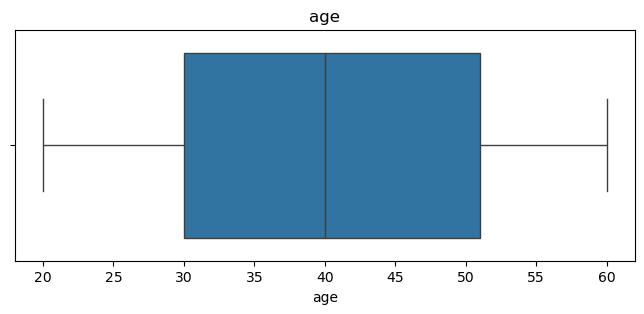

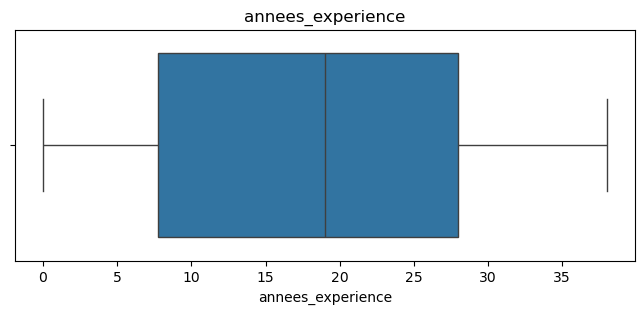

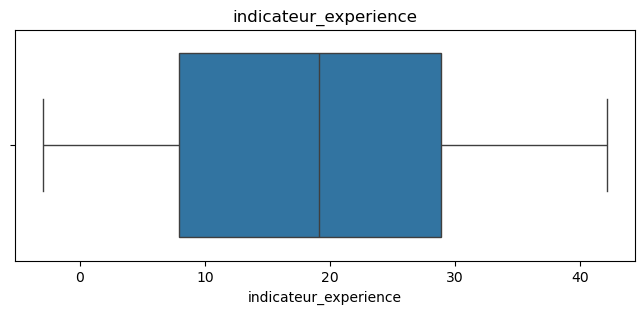

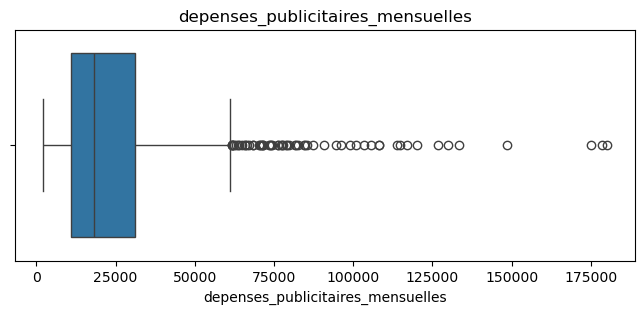

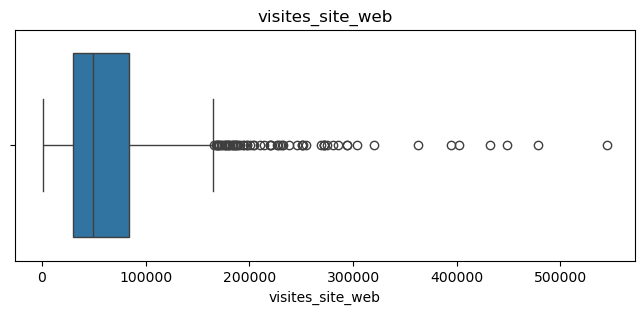

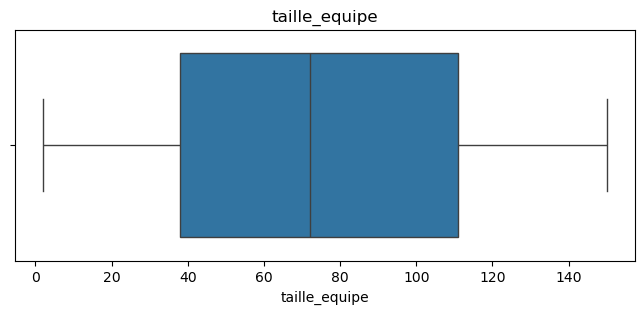

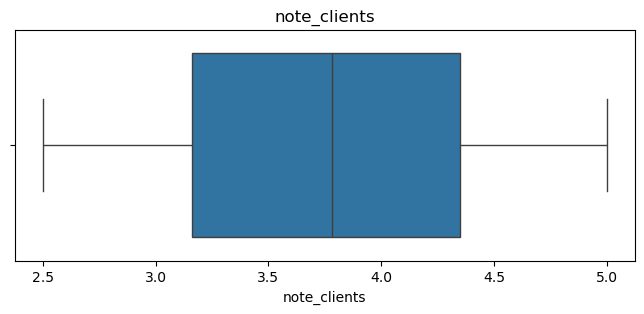

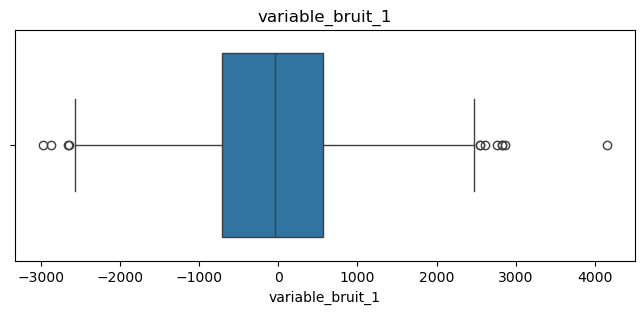

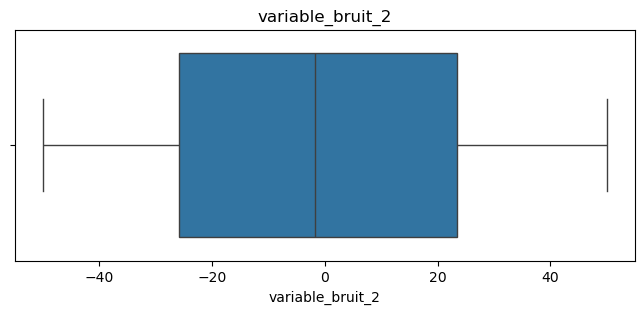

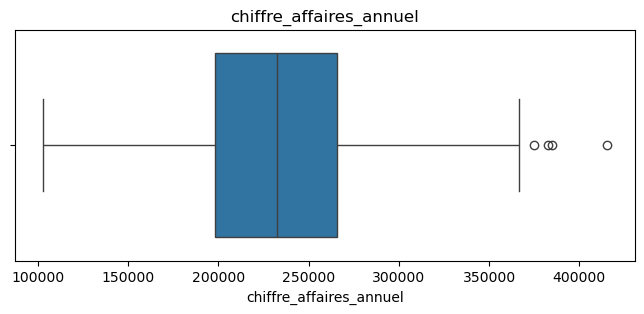

In [22]:
# Tracé des boxplots pour chaque variable
for column in df.select_dtypes(include="number").columns:
    fig,ax = plt.subplots(figsize=(8, 3))
    sns.boxplot(x=df[column],ax=ax)
    plt.title(column)
    plt.show()

## 1.6 Correlation entre les variables

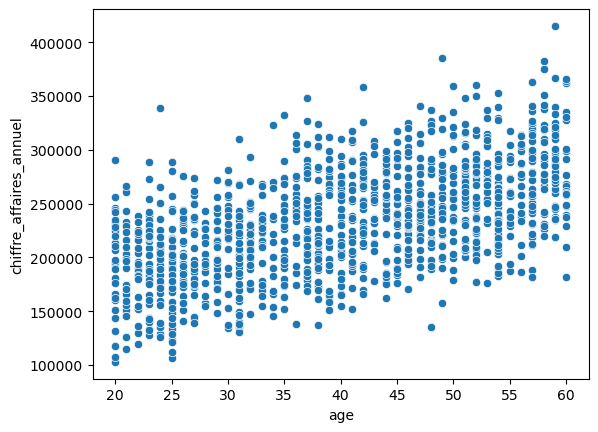

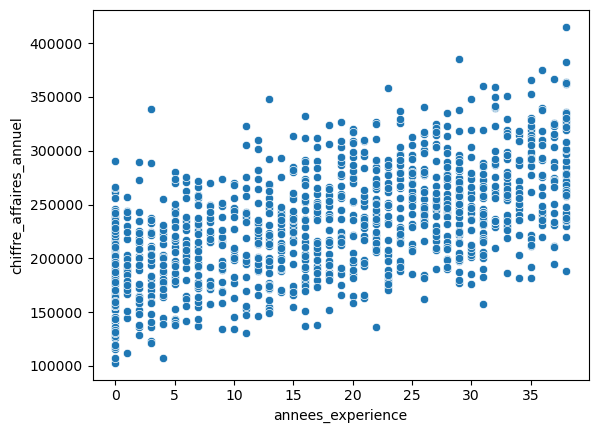

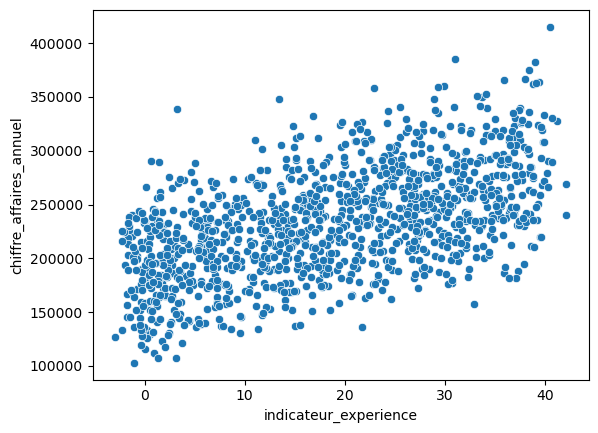

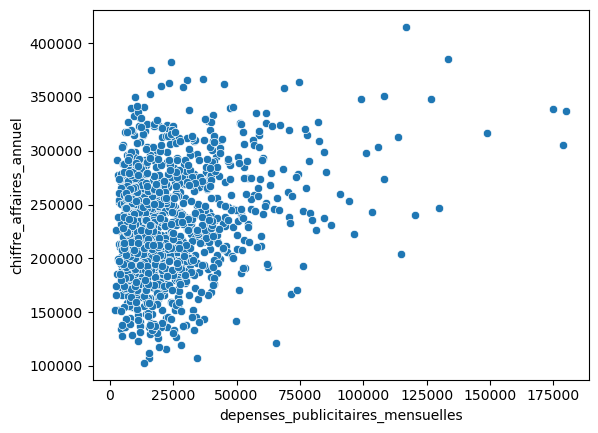

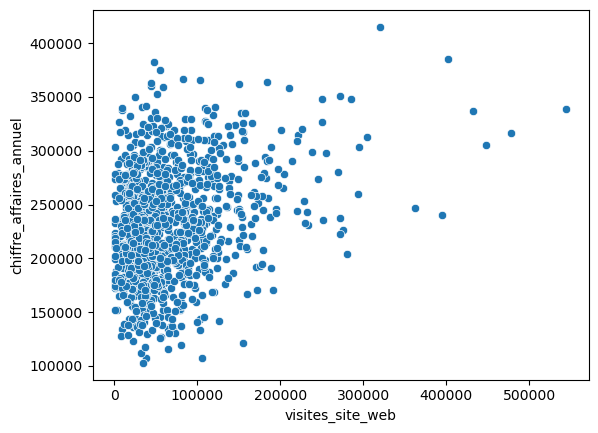

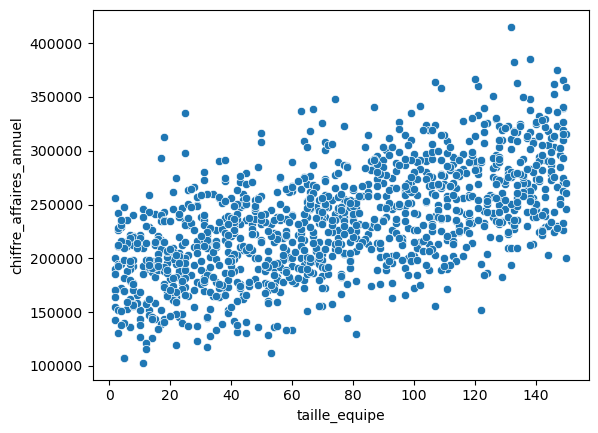

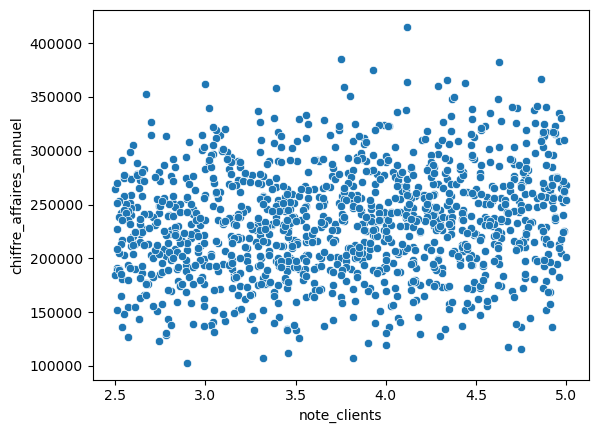

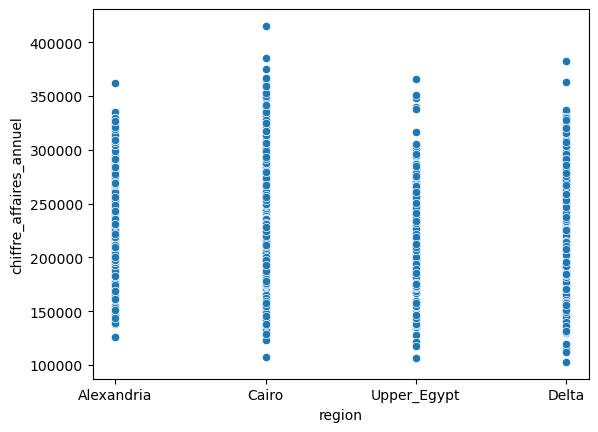

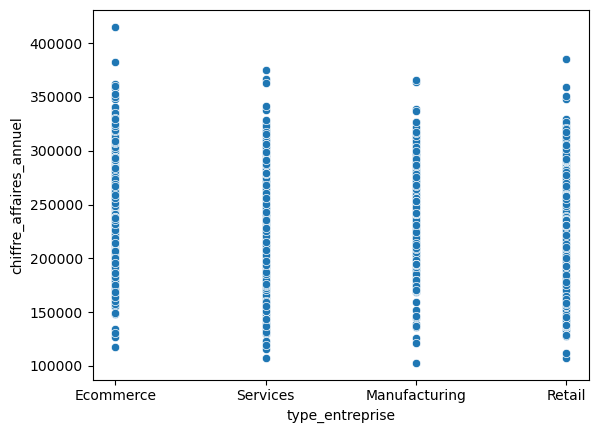

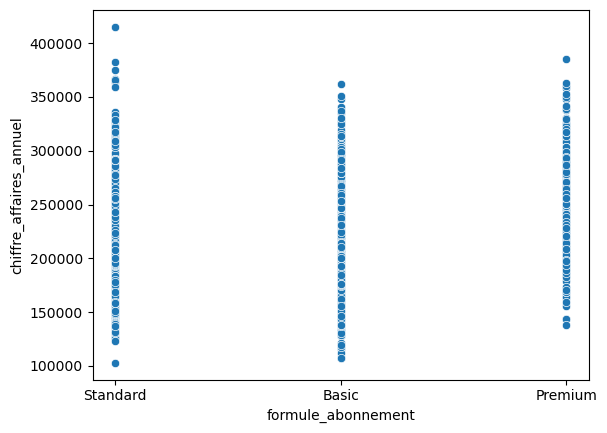

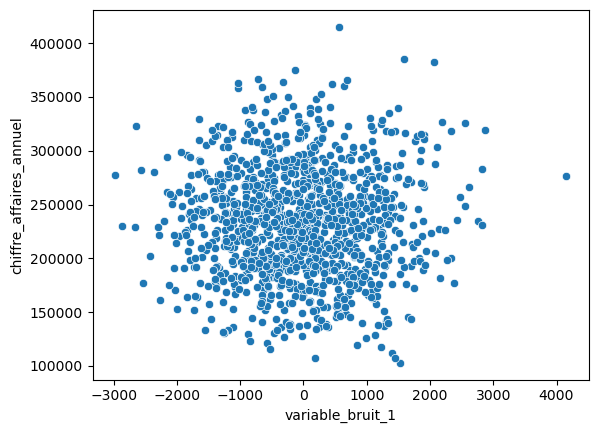

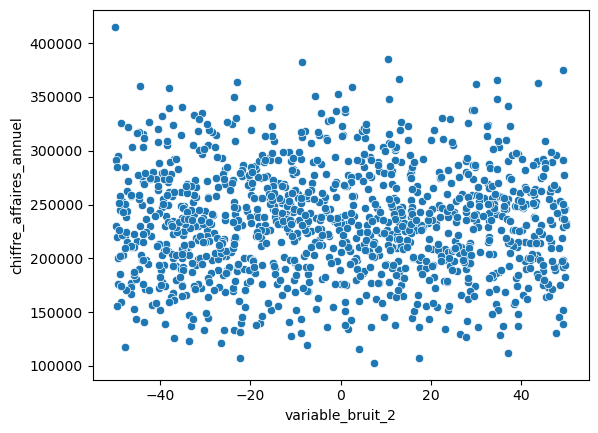

In [23]:
X = df.drop("chiffre_affaires_annuel", axis=1)
for i in X.columns:
    sns.scatterplot(x=X[i],y=df['chiffre_affaires_annuel'])
    plt.show()

<Axes: >

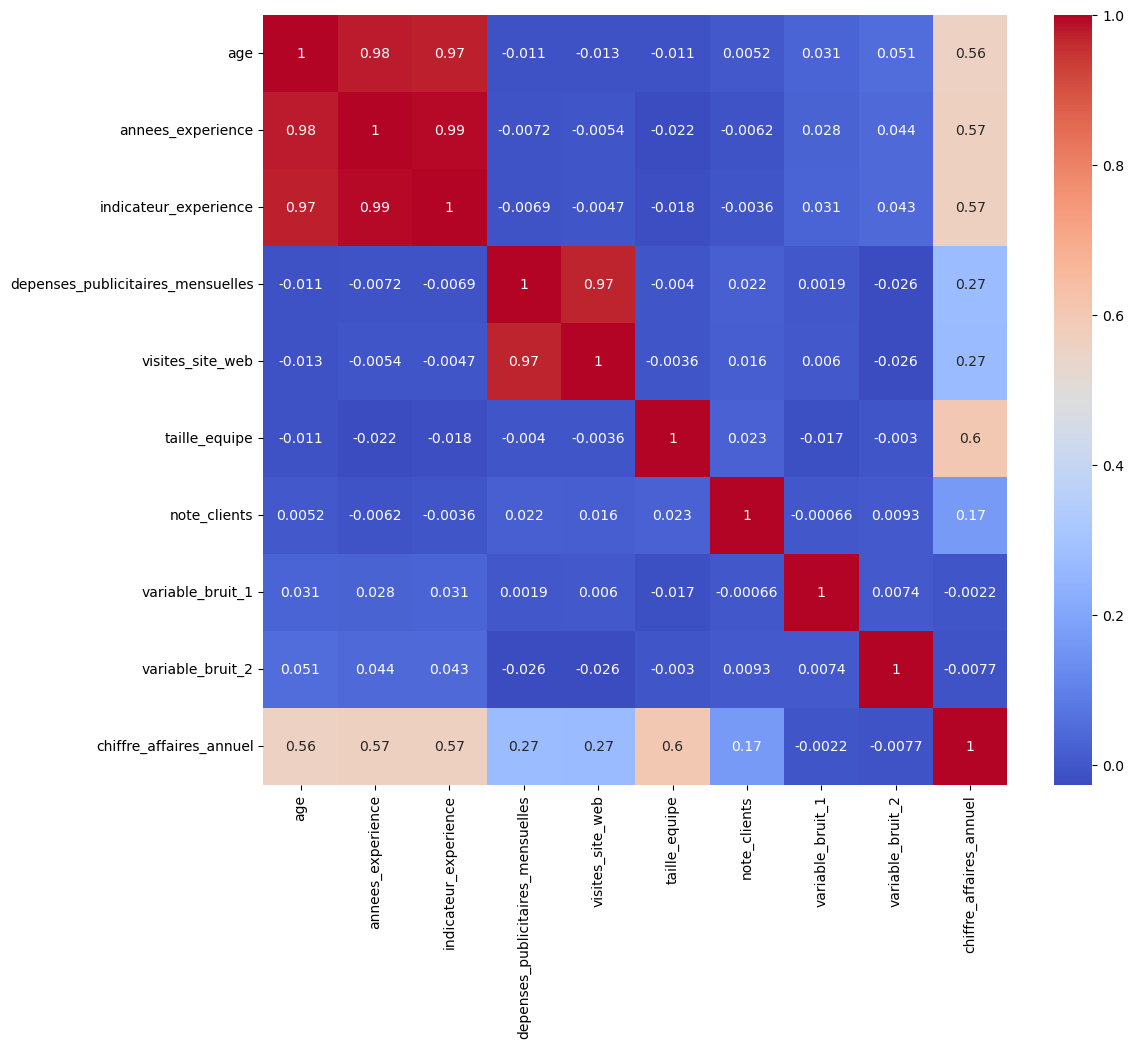

In [24]:
# Calcul de la matrice de corrélation
corr_matrix = df.corr(numeric_only=True)


plt.figure(figsize=(12, 10))
# Affichage de la matrice de corrélation sous forme de heatmap avec seaborn
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm")

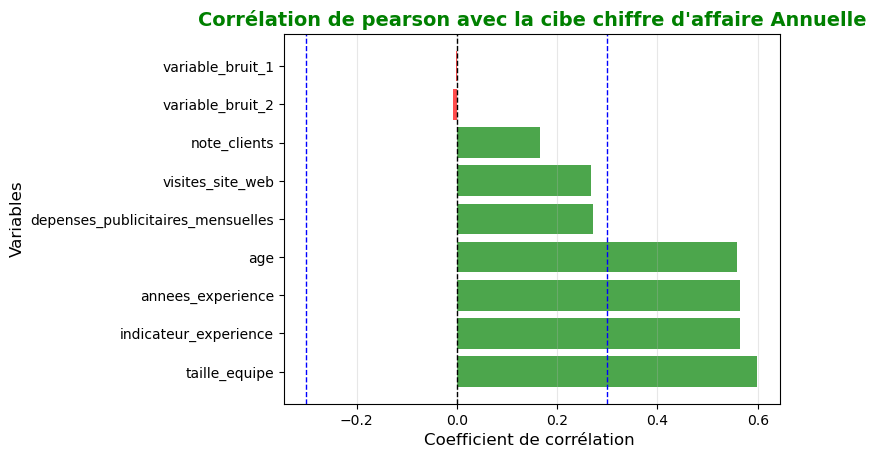

In [25]:
corr_target=corr_matrix['chiffre_affaires_annuel'].drop('chiffre_affaires_annuel').sort_values(ascending=False,key=abs)
corr_target_df=pd.DataFrame({
    'variable':corr_target.index,
    'correlation':corr_target.values,
    'valeur absolue':abs(corr_target.values)}).sort_values('valeur absolue',ascending=False)
corr_target_df.head()

colors=['green' if x>0 else "red" for x in corr_target_df['correlation']]
plt.barh(corr_target_df['variable'], corr_target_df['correlation'],color=colors,alpha=0.7)
plt.xlabel('Coefficient de corrélation ', fontsize=12)
plt.ylabel('Variables', fontsize=12)
plt.title("Corrélation de pearson avec la cibe chiffre d'affaire Annuelle", fontsize=14, fontweight='bold',color='green')
plt.grid(alpha=0.3,axis='x')
plt.axvline(x=0, color='black', linestyle='--', linewidth=1)
plt.axvline(x=0.3, color='blue', linestyle='--', linewidth=1, label='Seuil = ±0,3')
plt.axvline(x=-0.3, color='blue', linestyle='--', linewidth=1)
plt.show()

### Interpréter l’exploration
Les histogrammes et boxplots décrivent les distributions ; les nuages de points examinent les associations avec la cible. Les corrélations mesurent une association, pas une causalité. Une faible corrélation de Pearson peut masquer une relation non linéaire ou une contribution conjointe.

**Limite de cette version :** cette exploration est réalisée sur la base complète. Pour une évaluation finale plus stricte, réserver le test avant l’exploration qui influence les choix.

# Étape 2 — Nettoyage et prétraitement

## 2.1 Gestion des valeurs manquantes

In [26]:
df_copy = df.copy()
n_manquantes = int(df_copy.isna().sum().sum())
print(f"Nombre de valeurs manquantes : {n_manquantes}")
if n_manquantes:
    raise ValueError("Définir une imputation sur le train avant de continuer.")

Nombre de valeurs manquantes : 0


## 2.2 Encodage des variables


In [27]:
# Créer l'encodeur
encodeur = OneHotEncoder(sparse_output=False)
# Encoder la variable type_entreprise
resultat = encodeur.fit_transform(df[["type_entreprise"]])

# Construire le DataFrame des colonnes encodées
df_ohe = pd.DataFrame(resultat, columns=encodeur.get_feature_names_out(["type_entreprise"]), index=df.index)

print("One-hot encoding :")
df_ohe.head()

One-hot encoding :


,type_entreprise_Ecommerce,type_entreprise_Manufacturing,type_entreprise_Retail,type_entreprise_Services
0,1.0,0.0,0.0,0.0
1,0.0,0.0,0.0,1.0
2,0.0,1.0,0.0,0.0
3,0.0,0.0,0.0,1.0
4,0.0,0.0,0.0,1.0


In [28]:
encodeur1 = OneHotEncoder(sparse_output=False)

resultat1 = encodeur1.fit_transform(df[["region"]])

df_ohe1 = pd.DataFrame(resultat1,columns=encodeur1.get_feature_names_out(["region"]), index=df.index)

df_ohe1.head()

,region_Alexandria,region_Cairo,region_Delta,region_Upper_Egypt
0,1.0,0.0,0.0,0.0
1,0.0,1.0,0.0,0.0
2,0.0,0.0,0.0,1.0
3,0.0,1.0,0.0,0.0
4,0.0,1.0,0.0,0.0


In [29]:
encodeur2=OneHotEncoder(sparse_output=False)

resultat2=encodeur2.fit_transform(df[["formule_abonnement"]])
df_ohe2=pd.DataFrame(resultat2,columns=encodeur2.get_feature_names_out(["formule_abonnement"]), index=df.index)
df_ohe2.head()

,formule_abonnement_Basic,formule_abonnement_Premium,formule_abonnement_Standard
0,0.0,0.0,1.0
1,1.0,0.0,0.0
2,1.0,0.0,0.0
3,0.0,0.0,1.0
4,0.0,0.0,1.0


### Pourquoi encoder ?
Le One-Hot crée une colonne binaire par catégorie. La référence sera retirée avant le premier modèle, en section 3.2. Une région de référence n’a pas sa propre colonne, mais toutes ses observations restent dans les données.

**Amélioration nécessaire pour un pipeline réutilisable :** ici les encodeurs sont encore ajustés avant le découpage. Dans la prochaine version, les ajuster sur le train seulement et réutiliser `transform` sur le test. Une catégorie inconnue doit faire l’objet d’une stratégie explicite.

## 2.3 Retirer les colonnes textuelles après leur encodage

In [30]:
df=df.drop(columns=['formule_abonnement','region','type_entreprise'],axis=1)

In [31]:
df.head()

,age,annees_experience,indicateur_experience,depenses_publicitaires_mensuelles,visites_site_web,taille_equipe,note_clients,variable_bruit_1,variable_bruit_2,chiffre_affaires_annuel
0,23,0,-1.28,120217.22,394762,8,4.01,-294.95,-18.61,240086.12
1,51,29,28.75,54622.52,183214,56,2.89,-461.02,44.49,274237.97
2,46,20,23.79,41675.76,113096,141,2.89,-2156.89,-15.63,294387.86
3,37,13,15.73,13457.42,41326,91,4.64,682.77,21.51,247522.89
4,37,14,13.88,9281.03,11671,93,3.28,-1233.05,38.27,226068.17


## 2.4 Ajouter les colonnes encodées

In [32]:
df = pd.concat([df, df_ohe, df_ohe1, df_ohe2], axis=1)


In [33]:
df.head()

,age,annees_experience,indicateur_experience,depenses_publicitaires_mensuelles,visites_site_web,taille_equipe,note_clients,variable_bruit_1,variable_bruit_2,chiffre_affaires_annuel,...,type_entreprise_Manufacturing,type_entreprise_Retail,type_entreprise_Services,region_Alexandria,region_Cairo,region_Delta,region_Upper_Egypt,formule_abonnement_Basic,formule_abonnement_Premium,formule_abonnement_Standard
0,23,0,-1.28,120217.22,394762,8,4.01,-294.95,-18.61,240086.12,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
1,51,29,28.75,54622.52,183214,56,2.89,-461.02,44.49,274237.97,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2,46,20,23.79,41675.76,113096,141,2.89,-2156.89,-15.63,294387.86,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
3,37,13,15.73,13457.42,41326,91,4.64,682.77,21.51,247522.89,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,37,14,13.88,9281.03,11671,93,3.28,-1233.05,38.27,226068.17,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


## 2.5 Séparation entraînement/test

**Stratégie :**
- 80 % pour l’entraînement et 20 % pour le test.
- Graine aléatoire : 42, pour la reproductibilité.


In [34]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="chiffre_affaires_annuel")
y = df["chiffre_affaires_annuel"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## 2.6 Standardisation des variables numériques

In [35]:
# Variables numériques d'origine uniquement
colonnes_num = [
    "age",
    "annees_experience",
    "indicateur_experience",
    "depenses_publicitaires_mensuelles",
    "visites_site_web",
    "taille_equipe",
    "note_clients",
    "variable_bruit_1",
    "variable_bruit_2"
]

scaler = StandardScaler()

# Apprendre les paramètres sur l'entraînement et le transformer
X_train[colonnes_num] = scaler.fit_transform(X_train[colonnes_num])

# Appliquer les mêmes paramètres au test
X_test[colonnes_num] = scaler.transform(X_test[colonnes_num])

X_train.head()

,age,annees_experience,indicateur_experience,depenses_publicitaires_mensuelles,visites_site_web,taille_equipe,note_clients,variable_bruit_1,variable_bruit_2,type_entreprise_Ecommerce,type_entreprise_Manufacturing,type_entreprise_Retail,type_entreprise_Services,region_Alexandria,region_Cairo,region_Delta,region_Upper_Egypt,formule_abonnement_Basic,formule_abonnement_Premium,formule_abonnement_Standard
331,-0.427742,-0.101265,-0.211979,0.582689,0.156670,-1.624012,1.468213,-0.240924,1.165522,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
409,-1.701417,-1.471685,-1.456462,-0.407806,-0.405313,1.573614,0.654638,-0.369339,-1.629057,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
76,-0.597566,-0.700823,-0.551609,-0.263177,-0.407433,-0.326424,0.530533,2.435674,-1.596270,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
868,-0.173007,-0.015614,0.063195,-0.781366,-1.110213,-1.160588,1.385477,-1.140052,-1.024239,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
138,-0.512654,-0.700823,-0.622675,0.655241,0.452350,0.345541,-0.972513,0.551562,-0.456045,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


### Rôle de la standardisation
StandardScaler apprend la moyenne et l’écart-type sur le train, puis applique les mêmes valeurs au test : ce point est correct. Il ne rend pas automatiquement les distributions normales.

L’OLS sans pénalisation n’a pas besoin de standardisation pour ses prédictions ajustées. Les méthodes régularisées et SGD sont sensibles aux échelles. En validation croisée, le standardiseur doit être réajusté à l’intérieur de chaque pli.

# Étape 3 — Sélection des variables et régression linéaire
## 3.1 Sélection exploratoire par Pearson : |r| ≥ 0,3
On mesure sur le train l’association linéaire de chaque variable numérique avec la cible. Le seuil de 0,3 est un choix pédagogique, pas une règle statistique universelle. Les colonnes catégorielles encodées sont conservées à cette étape.

In [36]:
# Corrélation de Pearson avec la cible sur l'entraînement uniquement
corr_target_train = X_train[colonnes_num].corrwith(
    y_train, method="pearson"
).abs()

seuil = 0.3

# Variables numériques retenues et écartées
variables_retenues = corr_target_train[
    corr_target_train >= seuil
].sort_values(ascending=False)

variables_ecartees = corr_target_train[
    corr_target_train < seuil
].sort_values(ascending=False)

print("VARIABLES NUMÉRIQUES RETENUES :")
print(variables_retenues)

print("\nVARIABLES NUMÉRIQUES ÉCARTÉES :")
print(variables_ecartees)

# Conserver les colonnes One-Hot
colonnes_ohe = [
    colonne for colonne in X_train.columns
    if colonne not in colonnes_num
]

# Liste finale des features
selected_feature_names = variables_retenues.index.tolist() + colonnes_ohe

# Appliquer la même sélection au train et au test
X_train_selected = X_train[selected_feature_names].copy()
X_test_selected = X_test[selected_feature_names].copy()

print("\nNombre de features retenues :", X_train_selected.shape[1])
X_train_selected.head()

VARIABLES NUMÉRIQUES RETENUES :
taille_equipe            0.605714
annees_experience        0.551365
indicateur_experience    0.550970
age                      0.543640
dtype: float64

VARIABLES NUMÉRIQUES ÉCARTÉES :
depenses_publicitaires_mensuelles    0.292263
visites_site_web                     0.286639
note_clients                         0.164722
variable_bruit_1                     0.013593
variable_bruit_2                     0.004105
dtype: float64

Nombre de features retenues : 15


,taille_equipe,annees_experience,indicateur_experience,age,type_entreprise_Ecommerce,type_entreprise_Manufacturing,type_entreprise_Retail,type_entreprise_Services,region_Alexandria,region_Cairo,region_Delta,region_Upper_Egypt,formule_abonnement_Basic,formule_abonnement_Premium,formule_abonnement_Standard
331,-1.624012,-0.101265,-0.211979,-0.427742,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
409,1.573614,-1.471685,-1.456462,-1.701417,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
76,-0.326424,-0.700823,-0.551609,-0.597566,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
868,-1.160588,-0.015614,0.063195,-0.173007,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
138,0.345541,-0.700823,-0.622675,-0.512654,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


### Ce que la sélection a retenu dans l’exécution fournie
Les corrélations absolues de train sont environ : taille de l’équipe 0,606, années d’expérience 0,551, proxy d’expérience 0,551 et âge 0,544. Le seuil 0,3 écarte notamment les dépenses publicitaires (0,292), les visites (0,287) et la note clients (0,165).

Le faible écart entre 0,292 et 0,3 montre le caractère arbitraire du seuil. Ces variables ne sont pas démontrées inutiles : comparer une version complète à la version sélectionnée en validation serait pertinent.

## 3.2 Réduire la redondance et définir les références
`indicateur_experience` et `age` sont retirés dans cette expérience en raison de leur redondance avec les années d’expérience. Ce choix doit être examiné par des VIF recalculés après chaque retrait et, si on cherche le meilleur sous-ensemble prédictif, par validation sur le train.

On retire aussi une catégorie par groupe : **Ecommerce**, **Alexandria**, **Basic** deviennent les références. Une catégorie de référence est représentée par tous les indicateurs du groupe à zéro ; ses lignes ne sont pas supprimées. Cela évite une redondance parfaite avec l’intercept.

Les mêmes colonnes et le même ordre sont imposés au train et au test, avant `.fit()`.

In [37]:
colonnes_a_retirer = [
    "indicateur_experience", "age",
    "type_entreprise_Ecommerce", "region_Alexandria", "formule_abonnement_Basic"
]
X_train_selected = X_train_selected.drop(columns=colonnes_a_retirer, errors="ignore")
X_test_selected = X_test_selected[X_train_selected.columns].copy()
selected_feature_names = X_train_selected.columns.tolist()
assert X_train_selected.columns.equals(X_test_selected.columns)
print("Variables finales :", selected_feature_names)

Variables finales : ['taille_equipe', 'annees_experience', 'type_entreprise_Manufacturing', 'type_entreprise_Retail', 'type_entreprise_Services', 'region_Cairo', 'region_Delta', 'region_Upper_Egypt', 'formule_abonnement_Premium', 'formule_abonnement_Standard']


## 3.3 Créer et entraîner le modèle — .fit()

In [38]:
# Créer le modèle
modele_lineaire = LinearRegression()

# Apprendre les coefficients et la constante sur le train uniquement
modele_lineaire.fit(X_train_selected, y_train)

print("Constante :", modele_lineaire.intercept_)
coefficients = pd.DataFrame({
    "Variable": X_train_selected.columns,
    "Coefficient": modele_lineaire.coef_
})
display(coefficients)

Constante : 231956.01789219736


,Variable,Coefficient
0,taille_equipe,31013.956911
1,annees_experience,28020.880234
2,type_entreprise_Manufacturing,-6250.919973
3,type_entreprise_Retail,-14642.398543
4,type_entreprise_Services,-10734.276541
5,region_Cairo,8194.029089
6,region_Delta,-4174.789095
7,region_Upper_Egypt,-11490.642376
8,formule_abonnement_Premium,26443.291047
9,formule_abonnement_Standard,13530.380198


### Interprétation des coefficients
Les coefficients numériques correspondent ici à une augmentation d’un écart-type d’entraînement, puisque ces colonnes sont standardisées. Les coefficients des catégories décrivent des différences par rapport aux références, toutes les autres variables maintenues fixes.

La constante est la prédiction de base lorsque les variables numériques standardisées valent zéro et que les catégories de référence sont présentes. Ce n’est pas nécessairement une entreprise réelle. Aucun coefficient ne prouve un effet causal.

## 3.4 Prédire et calculer les métriques

In [39]:
X_test_selected = X_test_selected[X_train_selected.columns].copy()

# Prédictions
y_train_pred = modele_lineaire.predict(X_train_selected)
y_test_pred = modele_lineaire.predict(X_test_selected)

# Coefficient de détermination
r2_train = r2_score(y_train, y_train_pred)
r2_test = r2_score(y_test, y_test_pred)

# Erreur quadratique moyenne et sa racine
mse_train = mean_squared_error(y_train, y_train_pred)
mse_test = mean_squared_error(y_test, y_test_pred)
rmse_train = np.sqrt(mse_train)
rmse_test = np.sqrt(mse_test)

# Erreur absolue moyenne, demandée dans le TP
mae_train = mean_absolute_error(y_train, y_train_pred)
mae_test = mean_absolute_error(y_test, y_test_pred)

df_metrics = pd.DataFrame({
    "Métrique": ["R2", "MSE", "RMSE", "MAE"],
    "Train": [r2_train, mse_train, rmse_train, mae_train],
    "Test": [r2_test, mse_test, rmse_test, mae_test]
})
display(df_metrics)

,Métrique,Train,Test
0,R2,7.603673e-01,7.686666e-01
1,MSE,5.899312e+08,5.803577e+08
2,RMSE,2.428850e+04,2.409061e+04
3,MAE,1.906532e+04,1.887234e+04


## 3.5 Valeurs observées et prédites

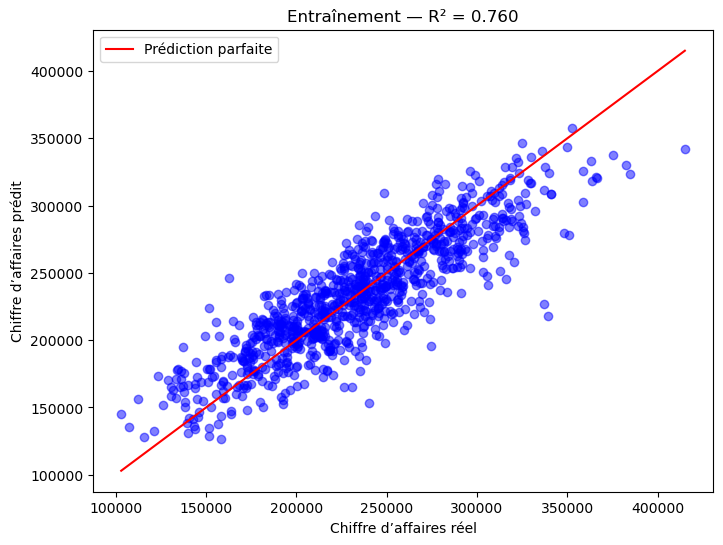

In [40]:
plt.figure(figsize=(8, 6))

plt.scatter(y_train, y_train_pred, color="blue", alpha=0.5)

# Adapter la diagonale aux montants de ton projet
minimum = min(y_train.min(), y_train_pred.min())
maximum = max(y_train.max(), y_train_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    color="red",
    label="Prédiction parfaite"
)

plt.xlabel("Chiffre d’affaires réel")
plt.ylabel("Chiffre d’affaires prédit")
plt.title(f"Entraînement — R² = {r2_score(y_train, y_train_pred):.3f}")
plt.legend()
plt.show()

# Étape 4 — Diagnostics du premier modèle linéaire
Ces diagnostics concernent d’abord la régression linéaire ajustée précédemment. Ils ne sont pas recalculés ici pour chaque modèle régularisé.

1. **Linéarité :** rechercher une structure courbe dans les résidus.
2. **Homoscédasticité :** examiner leur dispersion et le test de Breusch-Pagan/Koenker.
3. **Normalité :** examiner les résidus, pas imposer une distribution normale à chaque variable explicative.
4. **Multicolinéarité :** utiliser le VIF sur les variables explicatives avec une constante.

Le VIF peut être calculé après ce premier entraînement : il ne dépend pas de ce modèle, seulement de ses variables explicatives. Une suppression ultérieure imposerait de réentraîner les modèles.

## 4.1 Résidus, linéarité et homoscédasticité

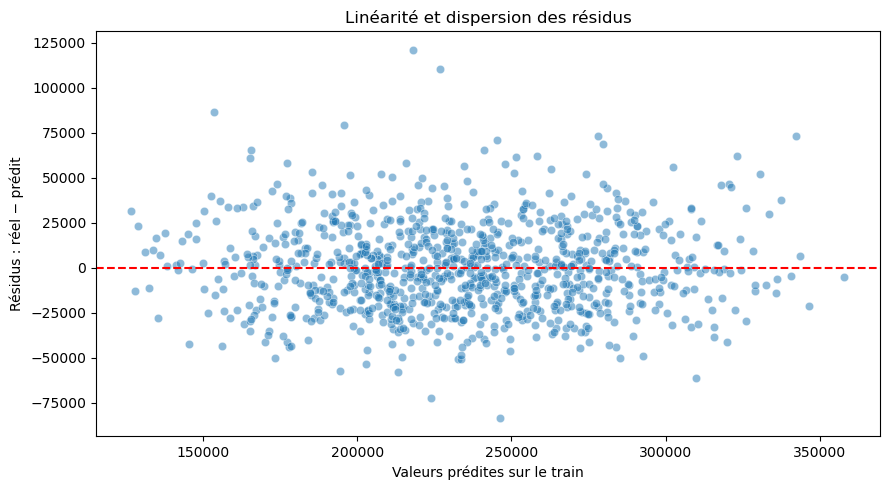

In [41]:
# Réutiliser les prédictions : aucun nouveau fit n'est nécessaire
residus_train = y_train - y_train_pred
plt.figure(figsize=(9, 5))
sns.scatterplot(x=y_train_pred, y=residus_train, alpha=0.5)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Valeurs prédites sur le train")
plt.ylabel("Résidus : réel − prédit")
plt.title("Linéarité et dispersion des résidus")
plt.tight_layout()
plt.show()

In [42]:
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.tools.tools import add_constant

# 1. Prédictions et résidus sur l'entraînement
y_train_pred = modele_lineaire.predict(X_train_selected)
residus = y_train - y_train_pred

# 2. Ajouter une constante pour le test statistique
X_train_bp = add_constant(X_train_selected, has_constant="add")

# 3. Effectuer le test : version robuste de Koenker par défaut
statistique, p_value, statistique_f, p_value_f = het_breuschpagan(
    residus, X_train_bp
)

print(f"Statistique LM : {statistique:.4f}")
print(f"P-value : {p_value:.4g}")

# 4. Interpréter au seuil de 5 %
if p_value < 0.05:
    print("Homoscédasticité rejetée : indice d'hétéroscédasticité.")
else:
    print("Homoscédasticité non rejetée : pas de preuve suffisante d'hétéroscédasticité.")

Statistique LM : 5.6922
P-value : 0.8404
Homoscédasticité non rejetée : pas de preuve suffisante d'hétéroscédasticité.


### Interpréter Breusch-Pagan/Koenker
H0 : la variance des erreurs est constante ; H1 : elle dépend des variables du test. Une p-value inférieure à 0,05 conduit à rejeter H0. Une p-value supérieure ne prouve pas que la variance soit parfaitement constante.

La sortie historique indiquait LM ≈ 5,692 et p ≈ 0,9566, avant la suppression des catégories redondantes. Cette p-value doit être **recalculée avec la matrice de rang correct** ; elle ne doit pas être reprise comme résultat définitif.

## 4.2 Normalité : graphique Q-Q et test de Shapiro-Wilk

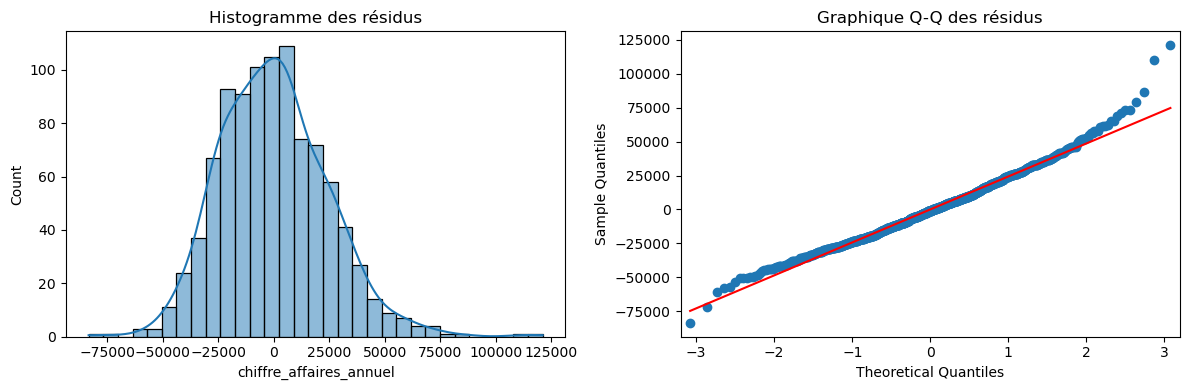

Shapiro-Wilk : W = 0.986568 ; p-value = 1.048e-07
Normalité rejetée au seuil de 5 %.


In [43]:
from scipy.stats import shapiro
import statsmodels.api as sm
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(residus, kde=True, ax=axs[0])
axs[0].set_title("Histogramme des résidus")
sm.qqplot(residus, line="s", ax=axs[1])
axs[1].set_title("Graphique Q-Q des résidus")
plt.tight_layout()
plt.show()
stat_res, p_value_normalite = shapiro(residus)
print(f"Shapiro-Wilk : W = {stat_res:.6f} ; p-value = {p_value_normalite:.4g}")
print("Normalité rejetée au seuil de 5 %." if p_value_normalite < 0.05
      else "Normalité non rejetée ; cela ne prouve pas une normalité parfaite.")

### Interpréter la normalité
La sortie d’origine indiquait W ≈ 0,9866 et p ≈ 1,05 × 10⁻⁷ : la normalité était rejetée au seuil de 5 %. Le test peut détecter de petits écarts sur un échantillon assez grand ; compléter avec le Q-Q plot.

La non-normalité ne rend pas automatiquement les prédictions inutilisables. Elle appelle surtout à la prudence pour l’inférence classique en petit échantillon. La qualité prédictive doit être évaluée séparément.

## 4.3 Multicolinéarité : VIF après les retraits
La constante participe au calcul des VIF, mais son propre VIF n’est pas interprété. Les seuils 5 et 10 sont des repères indicatifs.

In [44]:
# Recalculer les VIF avec une constante
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_const = sm.add_constant(
    X_train_selected.astype(float), has_constant="add"
)

vif = pd.DataFrame({
    "Variable": X_train_selected.columns,
    "VIF": [
        variance_inflation_factor(X_const.values, i)
        for i in range(1, X_const.shape[1])
    ]
})

print(vif.sort_values("VIF", ascending=False))

                        Variable       VIF
5                   region_Cairo  2.009929
6                   region_Delta  1.845572
7             region_Upper_Egypt  1.624592
3         type_entreprise_Retail  1.577275
4       type_entreprise_Services  1.542470
2  type_entreprise_Manufacturing  1.392460
8     formule_abonnement_Premium  1.167050
9    formule_abonnement_Standard  1.152086
0                  taille_equipe  1.014654
1              annees_experience  1.008854


### Interpréter les VIF obtenus
Les VIF enregistrés après retrait sont compris entre **1,009 et 2,010** : pas de forte multicolinéarité détectée parmi les dix variables restantes. Les indicateurs catégoriels peuvent eux aussi être examinés par le VIF.

Ce résultat explique pourquoi la régularisation n’est pas indispensable pour traiter une forte redondance dans cette sélection finale. Elle peut néanmoins être évaluée pour d’autres raisons, comme la généralisation ou la stabilité.

# Étape 5 — Ridge, Lasso et SGDRegressor

| Approche | Principe | Rôle dans ce projet |
|---|---|---|
| Régression linéaire | Minimise les erreurs au carré, sans pénalité | Modèle de référence interprétable |
| Ridge | Ajoute une pénalité L2 | Examiner la réduction des coefficients et leur stabilité |
| Lasso | Ajoute une pénalité L1 | Examiner si certains coefficients deviennent exactement nuls |
| SGDRegressor | Apprend par descente de gradient stochastique | Étudier une autre méthode d’optimisation d’un modèle linéaire |

SGD est une méthode d’optimisation : ce n’est pas une architecture non linéaire. Sa configuration par défaut ajoute une pénalisation L2. Ridge, Lasso et SGD ne minimisent donc pas exactement la même fonction objectif que l’OLS non pénalisé.

**Précision à retenir : Ridge et Lasso peuvent réduire l’instabilité liée à la multicolinéarité ; ils ne corrigent pas automatiquement l’hétéroscédasticité ni la non-normalité des résidus.**

## 5.1 Ridge — alpha initial de 1
`alpha=1` est une première configuration, pas une valeur optimale démontrée. Les colonnes numériques ont été standardisées ; les indicateurs restent en 0/1. La pénalisation des indicateurs dépend donc aussi de leurs fréquences.

In [45]:
from sklearn.linear_model import Ridge

# Même sélection et même ordre des colonnes
X_test_selected = X_test_selected[X_train_selected.columns].copy()

# Créer et entraîner Ridge
modele_ridge = Ridge(alpha=1.0)
modele_ridge.fit(X_train_selected, y_train)

print("Constante :", modele_ridge.intercept_)

coefficients = pd.DataFrame({
    "Variable": X_train_selected.columns,
    "Coefficient": modele_ridge.coef_
})

display(coefficients)


Constante : 231891.206484173


,Variable,Coefficient
0,taille_equipe,30981.282671
1,annees_experience,27992.653246
2,type_entreprise_Manufacturing,-6101.226715
3,type_entreprise_Retail,-14484.269226
4,type_entreprise_Services,-10581.736867
5,region_Cairo,8202.676771
6,region_Delta,-4115.657426
7,region_Upper_Egypt,-11370.189691
8,formule_abonnement_Premium,26209.919863
9,formule_abonnement_Standard,13403.957102


In [46]:
# Prédictions avec Ridge
y_train_pred_ridge = modele_ridge.predict(X_train_selected)
y_test_pred_ridge = modele_ridge.predict(X_test_selected)

# Évaluation
resultats_ridge = pd.DataFrame({
    "Métrique": ["R²", "MAE", "MSE", "RMSE"],
    "Train": [
        r2_score(y_train, y_train_pred_ridge),
        mean_absolute_error(y_train, y_train_pred_ridge),
        mean_squared_error(y_train, y_train_pred_ridge),
        np.sqrt(mean_squared_error(y_train, y_train_pred_ridge))
    ],
    "Test": [
        r2_score(y_test, y_test_pred_ridge),
        mean_absolute_error(y_test, y_test_pred_ridge),
        mean_squared_error(y_test, y_test_pred_ridge),
        np.sqrt(mean_squared_error(y_test, y_test_pred_ridge))
    ]
})

display(resultats_ridge)

,Métrique,Train,Test
0,R²,7.603606e-01,7.688138e-01
1,MAE,1.906174e+04,1.887093e+04
2,MSE,5.899479e+08,5.799885e+08
3,RMSE,2.428884e+04,2.408295e+04


## 5.2 Lasso — alpha initial de 1
Des coefficients nuls peuvent apparaître selon alpha. Avec une cible exprimée en montants élevés, alpha=1 peut être faible et produire un résultat proche de l’OLS ; cela ne démontre pas que Lasso est inutile.

In [47]:
from sklearn.linear_model import Lasso

#creer et entrainer lassso
modele_lasso = Lasso(alpha=1.0, max_iter=10000)
modele_lasso.fit(X_train_selected, y_train)

print("Constante :", modele_lasso.intercept_)

coeff=pd.DataFrame(
    {
        "variable":X_train_selected.columns,
        "coefficient":modele_lasso.coef_
        
    }
)
display(coeff)


Constante : 231942.53794707175


,variable,coefficient
0,taille_equipe,31012.898245
1,annees_experience,28019.887809
2,type_entreprise_Manufacturing,-6233.865872
3,type_entreprise_Retail,-14627.677194
4,type_entreprise_Services,-10718.918711
5,region_Cairo,8197.189236
6,region_Delta,-4164.447896
7,region_Upper_Egypt,-11478.002094
8,formule_abonnement_Premium,26435.046445
9,formule_abonnement_Standard,13523.586037


In [48]:
# Prédictions avec Lasso
y_train_pred_lasso = modele_lasso.predict(X_train_selected)
y_test_pred_lasso = modele_lasso.predict(X_test_selected)

# Évaluation
resultats_lasso = pd.DataFrame({
    "Métrique": ["R²", "MAE", "MSE", "RMSE"],
    "Train": [
        r2_score(y_train, y_train_pred_lasso),
        mean_absolute_error(y_train, y_train_pred_lasso),
        mean_squared_error(y_train, y_train_pred_lasso),
        np.sqrt(mean_squared_error(y_train, y_train_pred_lasso))
    ],
    "Test": [
        r2_score(y_test, y_test_pred_lasso),
        mean_absolute_error(y_test, y_test_pred_lasso),
        mean_squared_error(y_test, y_test_pred_lasso),
        np.sqrt(mean_squared_error(y_test, y_test_pred_lasso))
    ]
})

display(resultats_lasso)

,Métrique,Train,Test
0,R²,7.603673e-01,7.686750e-01
1,MAE,1.906512e+04,1.887248e+04
2,MSE,5.899313e+08,5.803367e+08
3,RMSE,2.428850e+04,2.409018e+04


## 5.3 SGDRegressor — apprentissage itératif
La graine fixe rend l’expérience reproductible. Surveiller tout avertissement de convergence. Les scores de l’ancienne exécution ne correspondent pas nécessairement à cette configuration reproductible.

In [49]:
from sklearn.linear_model import SGDRegressor

# Créer et entraîner le modèle
modele_sgd = SGDRegressor(max_iter=10000, tol=1e-3, random_state=42)
modele_sgd.fit(X_train_selected, y_train)
print("Constante :", modele_sgd.intercept_)

coeffsgd=pd.DataFrame(
    {
        "variable":X_train_selected.columns,
        "coefficient":modele_sgd.coef_
        
    }
)
display(coeffsgd)


Constante : [229233.52243642]


,variable,coefficient
0,taille_equipe,30928.473737
1,annees_experience,27958.816096
2,type_entreprise_Manufacturing,-5215.180891
3,type_entreprise_Retail,-13543.838122
4,type_entreprise_Services,-9649.331845
5,region_Cairo,10187.293615
6,region_Delta,-2022.613968
7,region_Upper_Egypt,-9129.033760
8,formule_abonnement_Premium,26982.637326
9,formule_abonnement_Standard,13897.164077


In [50]:

# Prédictions
y_train_pred_sgd = modele_sgd.predict(X_train_selected)
y_test_pred_sgd = modele_sgd.predict(X_test_selected)

# Évaluation
resultats_sgd = pd.DataFrame({
    "Métrique": ["R²", "MAE", "MSE", "RMSE"],
    "Train": [
        r2_score(y_train, y_train_pred_sgd),
        mean_absolute_error(y_train, y_train_pred_sgd),
        mean_squared_error(y_train, y_train_pred_sgd),
        np.sqrt(mean_squared_error(y_train, y_train_pred_sgd))
    ],
    "Test": [
        r2_score(y_test, y_test_pred_sgd),
        mean_absolute_error(y_test, y_test_pred_sgd),
        mean_squared_error(y_test, y_test_pred_sgd),
        np.sqrt(mean_squared_error(y_test, y_test_pred_sgd))
    ]
})

display(resultats_sgd)

,Métrique,Train,Test
0,R²,7.599825e-01,7.665125e-01
1,MAE,1.906708e+04,1.899517e+04
2,MSE,5.908786e+08,5.857620e+08
3,RMSE,2.430800e+04,2.420252e+04


## 5.4 Comparaison descriptive des résultats test
R² : plus élevé est généralement mieux ; MAE, MSE, RMSE : plus faible est mieux. MAE et RMSE ont l’unité du chiffre d’affaires, tandis que la MSE utilise cette unité au carré.

On sélectionne les métriques par leur nom, plutôt que leur position dans les tableaux. Un R² de 0,77 ne signifie pas « 77 % de prédictions exactes ».

Les écarts sur le test décrivent cette expérience. Ils ne doivent pas servir à ajuster plusieurs fois les variables ou alpha : utiliser la validation croisée sur le train pour ces choix.

Métrique,R²,MAE,MSE,RMSE
Linéaire,0.768667,18872.342261,5.803577e+08,24090.614927
Ridge,0.768814,18870.927085,5.799885e+08,24082.951438
Lasso,0.768675,18872.483621,5.803367e+08,24090.178919
SGD,0.766512,18995.170397,5.857620e+08,24202.520690


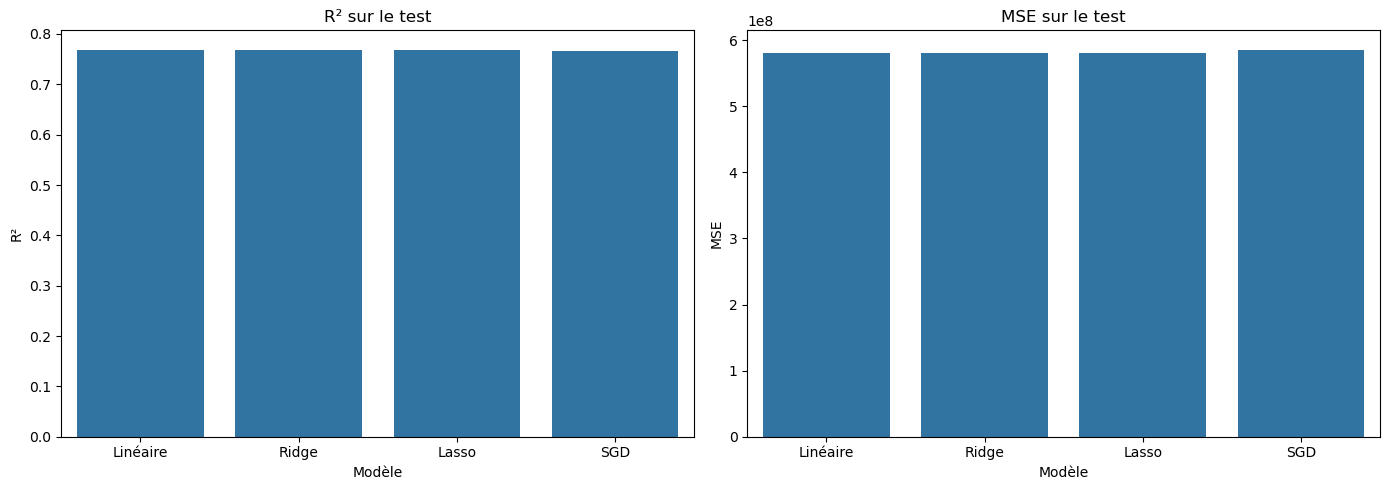

In [51]:
tableaux = {
    "Linéaire": df_metrics.replace({"Métrique": {"R2": "R²"}}),
    "Ridge": resultats_ridge,
    "Lasso": resultats_lasso,
    "SGD": resultats_sgd
}
comparaison = pd.DataFrame({
    nom: tableau.set_index("Métrique")["Test"] for nom, tableau in tableaux.items()
}).T
comparaison = comparaison[["R²", "MAE", "MSE", "RMSE"]]
display(comparaison)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metrique in zip(axes, ["R²", "MSE"]):
    sns.barplot(x=comparaison.index, y=comparaison[metrique], ax=ax)
    ax.set_title(f"{metrique} sur le test")
    ax.set_xlabel("Modèle")
    ax.set_ylabel(metrique)
plt.tight_layout()
plt.show()

## 5.5 Référence simple ajoutée
Une référence prédit toujours la moyenne du chiffre d’affaires du train. Elle aide à juger si les modèles apportent un progrès utile. Sa performance sera calculée à la prochaine exécution ; aucun score n’est inventé ici.

In [52]:
pred_reference = np.full(len(y_test), y_train.mean())
reference = pd.DataFrame({
    "R²": [r2_score(y_test, pred_reference)],
    "MAE": [mean_absolute_error(y_test, pred_reference)],
    "MSE": [mean_squared_error(y_test, pred_reference)],
    "RMSE": [np.sqrt(mean_squared_error(y_test, pred_reference))]
}, index=["Moyenne du train"])
display(reference)


,R²,MAE,MSE,RMSE
Moyenne du train,-0.00219,40050.959654,2.514245e+09,50142.245994


# Étape 6 — Synthèse des résultats historiques à confirmer
Ces chiffres sont transcrits des sorties du notebook fourni. Ils n’ont pas été recalculés après les corrections. La configuration de SGD a changé et le test de Breusch-Pagan doit être réexécuté. Ce tableau sert à documenter le travail effectué, pas à annoncer une nouvelle validation.

| Modèle | R² test | MAE test | MSE test | RMSE test |
|---|---:|---:|---:|---:|
| Linéaire | 0,768667 | 18 872,34 | 580 357 700 | 24 090,61 |
| Ridge | 0,768814 | 18 870,93 | 579 988 500 | 24 082,95 |
| Lasso | 0,768675 | 18 872,48 | 580 336 700 | 24 090,18 |
| SGD | 0,768146 | 18 910,26 | 581 664 500 | 24 117,72 |

### Que disent ces chiffres ?
- Les modèles sont très proches : une famille linéaire et une faible pénalisation peuvent donner des prédictions similaires.
- Ridge ne gagne qu’environ **0,00015 point de R²** et **7,66 unités de RMSE** sur l’OLS dans ces sorties. Un seul découpage ne permet pas d’affirmer une supériorité robuste.
- La MAE d’environ 18 900 correspond à une erreur absolue moyenne dans l’unité monétaire de la cible, encore inconnue. La tolérance métier n’est pas fournie : on ne peut pas conclure que cette erreur est acceptable en entreprise.
- Des scores train proches des scores test ne suffisent pas à démontrer l’absence de surapprentissage ou la représentativité du test.

### Conclusion du projet
Une régression linéaire constitue ici un point de départ simple et interprétable. Les configurations Ridge, Lasso et SGD testées ne présentent pas de gain matériel évident dans les sorties enregistrées. La décision finale doit être confirmée par une validation rigoureuse et un critère métier, sans chercher à créer artificiellement des écarts entre modèles.

# Étape 7 — Ajouts prioritaires
| Priorité | Ajout | Pourquoi ? | Statut |
|---|---|---|---|
| 1 | Réexécuter depuis un noyau redémarré avec le CSV | Vérifier l’ordre des cellules et recalculer les diagnostics après correction | À faire avec le dataset |
| 1 | Apprendre l’encodage uniquement sur le train | Ne pas apprendre les catégories à partir du test | À corriger dans le prochain pipeline |
| 1 | Validation croisée avec prétraitement et sélection dans chaque pli | Comparer des performances sans fuite entre plis | À ajouter |
| 2 | Régler alpha sur le train pour Ridge et Lasso | alpha=1 n’est pas nécessairement adapté à l’échelle de la cible | À ajouter après le pipeline |
| 2 | Comparer sélection Pearson et variables complètes | Le seuil 0,3 écarte des variables potentiellement utiles | À comparer en validation |
| 2 | Documenter source, devise et usage prévu | Interpréter les erreurs et la pertinence de l’objectif | À compléter |
| 3 | Sauvegarder prétraitements, sélection et modèle ensemble | Garantir les mêmes colonnes lors des nouvelles prédictions | Après stabilisation |

La référence simple et le Q-Q plot sont déjà ajoutés dans cette version. Pas besoin d’ajouter de nouveaux algorithmes avant de traiter les points prioritaires.

### Limites à annoncer
- Petit jeu de données, un seul découpage aléatoire, hyperparamètres non optimisés.
- Sélection univariée : relations conjointes et non linéaires potentiellement ignorées.
- Pas de validation temporelle possible sans date ; si plusieurs lignes concernent la même entreprise, un découpage par entreprise serait nécessaire.
- Les trois modèles régularisés ne résolvent pas automatiquement tous les écarts diagnostiqués sur l’OLS.
- Des références catégorielles doivent exister dans les données d’entraînement ; les catégories inédites nécessitent une gestion explicite.

### Formulation courte pour présenter le travail
« J’ai prédit le chiffre d’affaires annuel avec quatre approches linéaires. J’ai examiné les données, standardisé les variables numériques et corrigé les redondances de l’encodage catégoriel. Les modèles donnent des résultats proches sur le découpage étudié. Les prochaines étapes sont une validation sans fuite, le réglage des pénalités et la définition d’une erreur acceptable pour l’usage métier. »
